<a href="https://colab.research.google.com/github/G-Torres0/nometop/blob/main/Usando_matplotlib.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. EXPLORAÇÃO DOS DADOS

--- Primeiras Linhas ---
   Mes  Notebook  Mouse  Teclado
0  Jan        20     50       30
1  Fev        25     55       28
2  Mar        22     48       35
3  Abr        30     60       40
4  Mai        35     65       38

--- Dimensões do DataFrame (Linhas, Colunas) ---
(6, 4)

--- Estatísticas Descritivas ---
        Notebook      Mouse    Teclado
count   6.000000   6.000000   6.000000
mean   28.666667  58.000000  36.000000
std     7.788881   8.602325   6.356099
min    20.000000  48.000000  28.000000
25%    22.750000  51.250000  31.250000
50%    27.500000  57.500000  36.500000
75%    33.750000  63.750000  39.500000
max    40.000000  70.000000  45.000000

2. INDICADORES DE VENDAS (NumPy)

[Notebook]
  • Média mensal: 28.67 unidades
  • Maior valor: 40 unidades
  • Menor valor: 20 unidades

[Mouse]
  • Média mensal: 58.00 unidades
  • Maior valor: 70 unidades
  • Menor valor: 48 unidades

[Teclado]
  • Média mensal: 36.00 unidades
  • Maior valor: 45 unidades


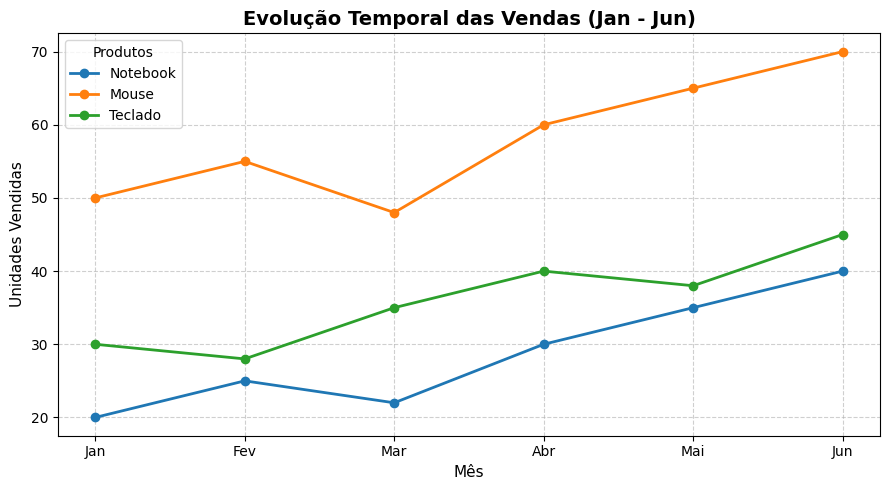

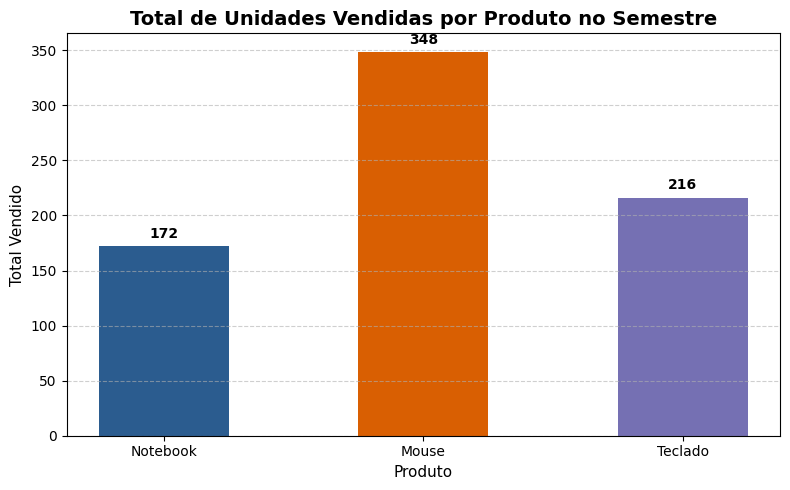

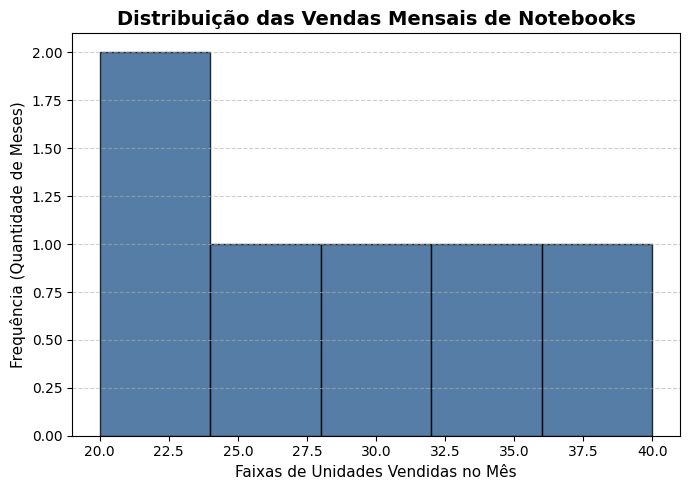

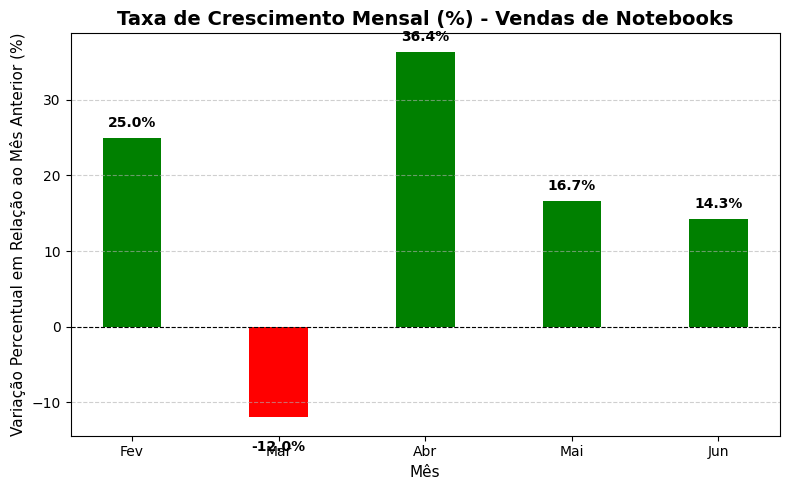

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# CÓDIGO INICIAL

dados = {
    "Mes": ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun"],
    "Notebook": [20, 25, 22, 30, 35, 40],
    "Mouse": [50, 55, 48, 60, 65, 70],
    "Teclado": [30, 28, 35, 40, 38, 45]
}

df = pd.DataFrame(dados)

print("="*50)
print("1. EXPLORAÇÃO DOS DADOS")
print("="*50)
print("\n--- Primeiras Linhas ---")
print(df.head())

print("\n--- Dimensões do DataFrame (Linhas, Colunas) ---")
print(df.shape)

print("\n--- Estatísticas Descritivas ---")
print(df.describe())




print("\n" + "="*50)
print("2. INDICADORES DE VENDAS (NumPy)")
print("="*50)

produtos = ["Notebook", "Mouse", "Teclado"]

for prod in produtos:
    valores = df[prod].to_numpy()  # Convertendo a coluna do pandas para array NumPy
    media = np.mean(valores)
    maximo = np.max(valores)
    minimo = np.min(valores)
    print(f"\n[{prod}]")
    print(f"  • Média mensal: {media:.2f} unidades")
    print(f"  • Maior valor: {maximo} unidades")
    print(f"  • Menor valor: {minimo} unidades")



#  (Gráfico de Linhas)

plt.figure(figsize=(9, 5))
for prod in produtos:
    plt.plot(df["Mes"], df[prod], marker='o', linewidth=2, label=prod)

plt.title("Evolução Temporal das Vendas (Jan - Jun)", fontsize=14, fontweight='bold')
plt.xlabel("Mês", fontsize=11)
plt.ylabel("Unidades Vendidas", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title="Produtos")
plt.tight_layout()
plt.show()


# Gráfico de Barras - Total por Produto

totais = df[produtos].sum()

plt.figure(figsize=(8, 5))
cores = ['#2b5c8f', '#d95f02', '#7570b3']
barras = plt.bar(totais.index, totais.values, color=cores, width=0.5)

plt.title("Total de Unidades Vendidas por Produto no Semestre", fontsize=14, fontweight='bold')
plt.xlabel("Produto", fontsize=11)
plt.ylabel("Total Vendido", fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Adiciona os rótulos numéricos sobre cada barra
for barra in barras:
    altura = barra.get_height()
    plt.text(barra.get_x() + barra.get_width()/2., altura + 5,
             f'{int(altura)}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


#
# Histograma - Vendas Mensais de Notebook

plt.figure(figsize=(7, 5))
plt.hist(df["Notebook"], bins=5, color='#2b5c8f', edgecolor='black', alpha=0.8)

plt.title("Distribuição das Vendas Mensais de Notebooks", fontsize=14, fontweight='bold')
plt.xlabel("Faixas de Unidades Vendidas no Mês", fontsize=11)
plt.ylabel("Frequência (Quantidade de Meses)", fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


# Variação Percentual Mensal (Notebook)

df["Var_Pct_Notebook"] = df["Notebook"].pct_change() * 100

plt.figure(figsize=(8, 5))
# Remove o primeiro mês (Jan) pois não possui variação percentual prévia
meses_var = df["Mes"][1:]
variacoes = df["Var_Pct_Notebook"][1:]

cores_var = ['green' if v >= 0 else 'red' for v in variacoes]
barras_var = plt.bar(meses_var, variacoes, color=cores_var, width=0.4)

plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.title("Taxa de Crescimento Mensal (%) - Vendas de Notebooks", fontsize=14, fontweight='bold')
plt.xlabel("Mês", fontsize=11)
plt.ylabel("Variação Percentual em Relação ao Mês Anterior (%)", fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)

for barra in barras_var:
    altura = barra.get_height()
    va_pos = 'bottom' if altura >= 0 else 'top'
    deslocamento = 1 if altura >= 0 else -3
    plt.text(barra.get_x() + barra.get_width()/2., altura + deslocamento,
             f'{altura:.1f}%', ha='center', va=va_pos, fontweight='bold')

plt.tight_layout()
plt.show()